In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import warnings
warnings.filterwarnings('ignore')

In [25]:
df = pd.read_csv('loan_data_v1.csv')

In [26]:
df.head()

,Unnamed: 0,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,41282,31.0,female,High School,31903.0,10,OWN,13672.0,VENTURE,12.66,0.43,10.0,637.0,Yes,NaN
1,23717,29.0,female,NaN,39365.0,3,RENT,9250.0,HOMEIMPROVEMENT,15.65,0.23,7.0,625.0,No,1.0
2,39085,27.0,male,Bachelor,150854.0,6,MORTGAGE,15628.0,PERSONAL,9.18,0.10,4.0,633.0,No,0.0
3,37196,27.0,female,Bachelor,57474.0,6,RENT,5000.0,MEDICAL,10.36,0.09,7.0,NaN,Yes,0.0
4,21819,29.0,female,Associate,61039.0,7,MORTGAGE,10000.0,MEDICAL,7.88,0.16,8.0,673.0,Yes,0.0


In [27]:
df.describe()

,Unnamed: 0,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,loan_status
count,7000.000000,6598.000000,7000.000000,7000.000000,6621.000000,7000.000000,7000.000000,7000.000000,6658.000000,6726.000000
mean,22423.845714,27.819794,79337.315857,5.409000,9529.274430,11.067064,0.138220,5.869429,633.298438,0.227178
std,12991.383097,5.908102,54590.972479,5.873579,6309.397161,3.014951,0.085775,3.873383,49.820148,0.419040
min,1.000000,20.000000,8000.000000,0.000000,500.000000,5.420000,0.000000,2.000000,418.000000,0.000000
25%,11176.750000,24.000000,47132.000000,1.000000,5000.000000,8.630000,0.070000,3.000000,603.000000,0.000000
50%,22341.000000,26.000000,66962.000000,4.000000,8000.000000,11.010000,0.120000,4.000000,640.000000,0.000000
75%,33662.000000,30.000000,96102.000000,8.000000,12000.000000,13.100000,0.190000,8.000000,670.000000,0.000000
max,44997.000000,70.000000,994605.000000,46.000000,35000.000000,20.000000,0.590000,30.000000,765.000000,1.000000


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7000 entries, 0 to 6999
Data columns (total 15 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Unnamed: 0                      7000 non-null   int64  
 1   person_age                      6598 non-null   float64
 2   person_gender                   6732 non-null   object 
 3   person_education                6644 non-null   object 
 4   person_income                   7000 non-null   float64
 5   person_emp_exp                  7000 non-null   int64  
 6   person_home_ownership           7000 non-null   object 
 7   loan_amnt                       6621 non-null   float64
 8   loan_intent                     7000 non-null   object 
 9   loan_int_rate                   7000 non-null   float64
 10  loan_percent_income             7000 non-null   float64
 11  cb_person_cred_hist_length      7000 non-null   float64
 12  credit_score                    66

In [29]:
df.isnull().sum()

Unnamed: 0                          0
person_age                        402
person_gender                     268
person_education                  356
person_income                       0
person_emp_exp                      0
person_home_ownership               0
loan_amnt                         379
loan_intent                         0
loan_int_rate                       0
loan_percent_income                 0
cb_person_cred_hist_length          0
credit_score                      342
previous_loan_defaults_on_file      0
loan_status                       274
dtype: int64

In [30]:
df.duplicated().sum()

0

In [31]:
plt.figure(figsize=(15,12))

<Figure size 1500x1200 with 0 Axes>

<Figure size 1500x1200 with 0 Axes>

In [32]:
# Data Preprocessing
print("=" * 50)
print("DATA PREPROCESSING")
print("=" * 50)

# Create a copy for preprocessing
df_processed = df.copy()

# Handle missing values
print("Handling missing values...")

# Numerical columns - fill with median
numerical_columns = ['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 
                   'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 
                   'credit_score']

for col in numerical_columns:
    if col in df_processed.columns:
        df_processed[col] = df_processed[col].fillna(df_processed[col].median())
        print(f"Filled missing values in {col} with median: {df_processed[col].median():.2f}")

# Categorical columns - fill with mode
categorical_columns = ['person_gender', 'person_education', 'person_home_ownership', 
                     'loan_intent', 'previous_loan_defaults_on_file']

for col in categorical_columns:
    if col in df_processed.columns:
        mode_value = df_processed[col].mode()[0] if not df_processed[col].mode().empty else 'Unknown'
        df_processed[col] = df_processed[col].fillna(mode_value)
        print(f"Filled missing values in {col} with mode: {mode_value}")

# Handle target variable
df_processed['loan_status'] = df_processed['loan_status'].fillna(0)  # Assuming NaN means approved

# Encode categorical variables
print("\nEncoding categorical variables...")
label_encoders = {}

for col in categorical_columns:
    if col in df_processed.columns:
        le = LabelEncoder()
        df_processed[col] = le.fit_transform(df_processed[col].astype(str))
        label_encoders[col] = le
        print(f"Encoded {col} with {len(le.classes_)} categories: {list(le.classes_)}")

# Verify no missing values remain
print(f"\nRemaining missing values: {df_processed.isnull().sum().sum()}")

print("\nProcessed dataset shape:", df_processed.shape)
print("Processed dataset info:")
print(df_processed.info())

DATA PREPROCESSING
Handling missing values...
Filled missing values in person_age with median: 26.00
Filled missing values in person_income with median: 66962.00
Filled missing values in person_emp_exp with median: 4.00
Filled missing values in loan_amnt with median: 8000.00
Filled missing values in loan_int_rate with median: 11.01
Filled missing values in loan_percent_income with median: 0.12
Filled missing values in cb_person_cred_hist_length with median: 4.00
Filled missing values in credit_score with median: 640.00
Filled missing values in person_gender with mode: male
Filled missing values in person_education with mode: Bachelor
Filled missing values in person_home_ownership with mode: RENT
Filled missing values in loan_intent with mode: EDUCATION
Filled missing values in previous_loan_defaults_on_file with mode: Yes

Encoding categorical variables...
Encoded person_gender with 2 categories: ['female', 'male']
Encoded person_education with 5 categories: ['Associate', 'Bachelor', '

In [33]:
df.isnull().sum()

Unnamed: 0                          0
person_age                        402
person_gender                     268
person_education                  356
person_income                       0
person_emp_exp                      0
person_home_ownership               0
loan_amnt                         379
loan_intent                         0
loan_int_rate                       0
loan_percent_income                 0
cb_person_cred_hist_length          0
credit_score                      342
previous_loan_defaults_on_file      0
loan_status                       274
dtype: int64

Feature columns used for modeling:
['person_age', 'person_gender', 'person_education', 'person_income', 'person_emp_exp', 'person_home_ownership', 'loan_amnt', 'loan_intent', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file']

X shape: (7000, 13), y shape: (7000,)

Training set size: 5600
Test set size: 1400
Training set class distribution:
loan_status
0.0    0.781786
1.0    0.218214
Name: proportion, dtype: float64
Test set class distribution:
loan_status
0.0    0.781429
1.0    0.218571
Name: proportion, dtype: float64

MODEL TRAINING - RANDOM FOREST

MODEL EVALUATION
Accuracy: 0.9036

Classification Report:
              precision    recall  f1-score   support

         0.0       0.92      0.96      0.94      1094
         1.0       0.83      0.71      0.76       306

    accuracy                           0.90      1400
   macro avg       0.87      0.83      0.85      1400
weighted avg       0.90      0.90      0.9

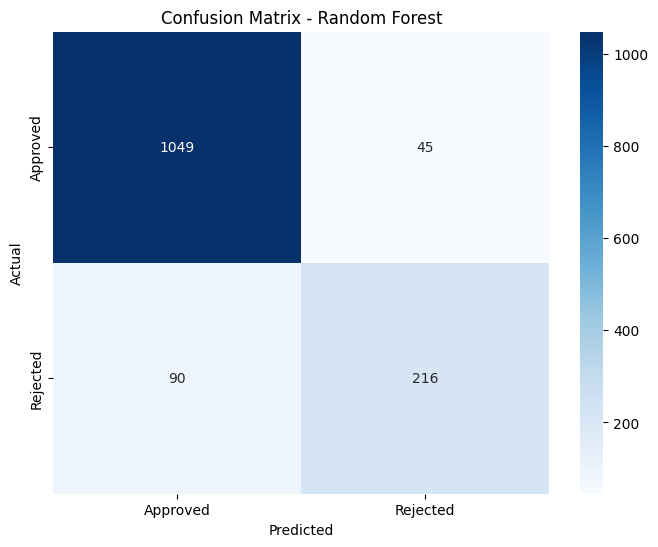


Feature Importance:
                           feature  importance
12  previous_loan_defaults_on_file    0.267321
8                    loan_int_rate    0.194437
9              loan_percent_income    0.173958
3                    person_income    0.108249
5            person_home_ownership    0.066319
6                        loan_amnt    0.045380
11                    credit_score    0.043807
7                      loan_intent    0.028366
0                       person_age    0.020924
4                   person_emp_exp    0.018982
10      cb_person_cred_hist_length    0.017518
2                 person_education    0.010397
1                    person_gender    0.004342


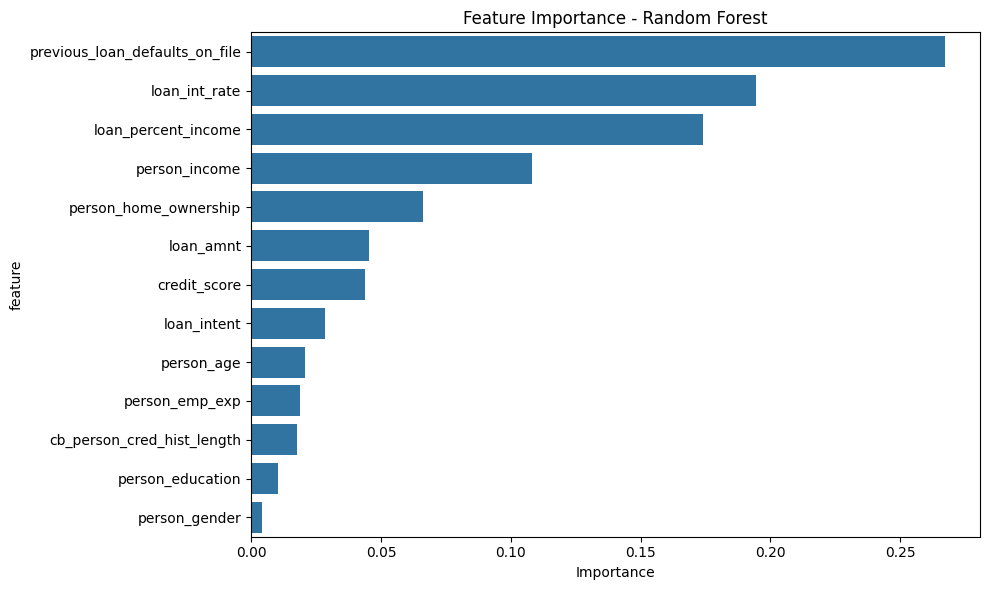


Additional Metrics:
Precision: 0.8276
Recall: 0.7059
F1-Score: 0.7619
ROC-AUC: 0.9591


In [34]:
# Prepare features and target
# Exclude the first column (index) and any other non-predictive columns
feature_columns = [col for col in df_processed.columns if col not in ['loan_status', 'Unnamed: 0'] and col in df_processed.columns]

X = df_processed[feature_columns]
y = df_processed['loan_status']

print("Feature columns used for modeling:")
print(feature_columns)
print(f"\nX shape: {X.shape}, y shape: {y.shape}")

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTraining set size: {X_train.shape[0]}")
print(f"Test set size: {X_test.shape[0]}")
print(f"Training set class distribution:\n{y_train.value_counts(normalize=True)}")
print(f"Test set class distribution:\n{y_test.value_counts(normalize=True)}")

# Scale numerical features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Random Forest model
print("\n" + "=" * 50)
print("MODEL TRAINING - RANDOM FOREST")
print("=" * 50)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=10)
rf_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred = rf_model.predict(X_test_scaled)
y_pred_proba = rf_model.predict_proba(X_test_scaled)

# Evaluate the model
print("\n" + "=" * 50)
print("MODEL EVALUATION")
print("=" * 50)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
print(cm)

# Visualize confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
           xticklabels=['Approved', 'Rejected'], 
           yticklabels=['Approved', 'Rejected'])
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

# Feature importance
feature_importance = pd.DataFrame({
    'feature': feature_columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nFeature Importance:")
print(feature_importance)

# Plot feature importance
plt.figure(figsize=(10, 6))
sns.barplot(data=feature_importance, x='importance', y='feature')
plt.title('Feature Importance - Random Forest')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

# Additional evaluation metrics
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba[:, 1])

print("\nAdditional Metrics:")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")